# Tuần 4 — Đánh giá cuối trên test, phân tích lỗi, hoàn thiện báo cáo
Thời lượng dự kiến: **5 giờ** (khoảng 2 giờ notebook, 3 giờ hoàn thiện báo cáo)

**Mục tiêu.** Sau tuần này, sinh viên có thể:
1. đánh giá mô hình đã khóa trên test **một lần** và diễn giải theo nghiệp vụ;
2. giải thích chênh lệch giữa điểm validation và điểm test;
3. phân tích lỗi theo nhóm khách hàng và theo từng trường hợp, phân biệt điều quan sát được với điều phỏng đoán;
4. viết kết luận tương xứng với bằng chứng.

**Cách dùng notebook.** Mỗi mục được đánh dấu bằng một nhãn:
`[KIẾN THỨC]` nội dung cần đọc · `[MINH HỌA]` ô mã có sẵn, chạy và quan sát kết quả ·
`[YÊU CẦU]` phần sinh viên thực hiện: thay mỗi chỗ `None` hoặc `____` bằng mã phù hợp ·
`[TỰ KIỂM TRA]` ô kiểm tra tự động, in **ĐẠT** khi kết quả đúng ·
`[BÁO CÁO]` ghi câu trả lời ngắn vào ô văn bản để đưa vào báo cáo ·
`[CÂU HỎI SUY NGẪM]` câu hỏi để sinh viên tự trả lời trước; gợi ý ở cuối notebook.

> **Sổ tay thư viện** (`00_so_tay_thu_vien.pdf`, phát kèm đồ án) — các mục cần tra cứu trong tuần này: mục 7 (đánh giá mô hình); mục 10 (đọc thông báo lỗi). Mỗi mục có đoạn mã mẫu chạy trên chính dữ liệu của đồ án, kết quả in ra và các lỗi thường gặp.

## Thiết lập
`[MINH HỌA]` Ô dưới đây nạp thư viện, tải dữ liệu và chia thành ba tập. Mã này **do giảng viên cung cấp, không thuộc phần đánh giá**; sinh viên chạy ô này mỗi khi mở notebook (khoảng 15 giây ở lần đầu).

In [1]:
# Dùng cùng phiên bản scikit-learn đã cài ở tuần 3
%pip install -q "scikit-learn==1.9.1"

In [2]:
import io, json, zipfile, hashlib, datetime, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

# Dữ liệu UCI Bank Marketing, tệp bank-full.csv; mã SHA-256 bảo đảm mọi sinh viên dùng cùng một tệp
NGUON = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
SHA256 = "d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d"

def doc_du_lieu():
    """Đọc du_lieu/bank-full.csv; nếu chưa có thì tải từ UCI (tệp nén lồng hai lớp) và lưu lại."""
    tep = Path("du_lieu/bank-full.csv")
    if not tep.exists():
        tep.parent.mkdir(exist_ok=True)
        ngoai = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(NGUON, timeout=30).read()))
        trong = zipfile.ZipFile(io.BytesIO(ngoai.read("bank.zip")))
        tep.write_bytes(trong.read("bank-full.csv"))
    assert hashlib.sha256(tep.read_bytes()).hexdigest() == SHA256, "Tệp dữ liệu không đúng phiên bản của đồ án."
    df = pd.read_csv(tep, sep=";")
    return df.assign(ma_dong=[f"dong:{i + 1:05d}" for i in range(len(df))])

du_lieu = doc_du_lieu()
train_val, test = train_test_split(du_lieu, test_size=0.2, stratify=du_lieu["y"], random_state=42)
train, val = train_test_split(train_val, test_size=0.25, stratify=train_val["y"], random_state=42)
train, val, test = (d.reset_index(drop=True) for d in (train, val, test))
print("Kích thước train / validation / test:", len(train), len(val), len(test), "(theo đề: 27126 / 9042 / 9043)")

# Thuộc tính đầu vào của mô hình (đã loại duration — lý do ở tuần 1, mục 1.6)
THUOC_TINH_SO = ["age", "balance", "day", "campaign", "pdays", "previous"]
THUOC_TINH_PL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

def chi_so(y_that, y_du_doan):
    """Các chỉ số chính, với yes là lớp cần phát hiện (tính bằng scikit-learn)."""
    p, r, f, _ = precision_recall_fscore_support(y_that, y_du_doan, labels=["yes"], zero_division=0)
    return {"accuracy": accuracy_score(y_that, y_du_doan), "precision_yes": p[0], "recall_yes": r[0], "f1_yes": f[0]}

Kích thước train / validation / test: 27126 9042 9043 (theo đề: 27126 / 9042 / 9043)


`[YÊU CẦU]` Sinh viên điền mã số sinh viên. Ba chữ số cuối là **seed cá nhân** dùng để lấy mẫu sáu trường hợp lỗi ở mục 4.5.

In [ ]:
MSSV = "3124411226"          # YÊU CẦU: điền mã số sinh viên
S_SV = int(MSSV[-3:]) if MSSV[-3:].isdigit() else None
assert S_SV is not None, "CHƯA ĐẠT: cần điền MSSV rồi chạy lại ô này."
print("ĐẠT: seed cá nhân S_SV =", S_SV)

ĐẠT: seed cá nhân S_SV = 226


## 4.1 `[YÊU CẦU]` Nạp lại quyết định đã khóa
Yêu cầu sinh viên dán dòng `QUYET_DINH` của tuần 3. Ô tự kiểm tra sẽ dựng lại đúng mô hình đó và xác nhận F1-yes trên validation **trùng** với số đã ghi, tức là đang đánh giá đúng mô hình đã khóa.

In [ ]:
QUYET_DINH = {"mssv": "3124411226", "mo_hinh": "E5", "so_no_ron": 256, "nguong": 0.6, "f1_yes_val": 0.4806, "thoi_diem": "2026-11-18 09:09"}     # YÊU CẦU: dán nguyên dòng in ra ở mục 3.7 tuần 3, ví dụ:
# QUYET_DINH = {"mssv": "...", "mo_hinh": "E4", "so_no_ron": 64, "nguong": 0.7, "f1_yes_val": 0.4512, "thoi_diem": "2026-11-20 21:40"}

In [5]:
# [TỰ KIỂM TRA]
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import FunctionTransformer
assert isinstance(QUYET_DINH, dict), "CHƯA ĐẠT: cần dán dòng QUYET_DINH của tuần 3."
assert QUYET_DINH.get("mssv") == MSSV, "CHƯA ĐẠT: MSSV trong QUYET_DINH không khớp MSSV hiện tại."
assert {"mo_hinh", "so_no_ron", "nguong", "f1_yes_val"}.issubset(QUYET_DINH), "CHƯA ĐẠT: thiếu trường bắt buộc trong QUYET_DINH."
assert QUYET_DINH["mo_hinh"] in {"E1", "E2", "E3", "E4", "E5"} and 0 < QUYET_DINH["nguong"] < 1, "CHƯA ĐẠT: mô hình hoặc ngưỡng không hợp lệ."
if QUYET_DINH["mo_hinh"] == "E3":
    assert isinstance(QUYET_DINH["so_no_ron"], int) and QUYET_DINH["so_no_ron"] > 0, "CHƯA ĐẠT: E3 cần số nơ-ron nguyên dương."

def tao_tien_xu_ly(them_pl=()):
    return make_column_transformer((OneHotEncoder(handle_unknown="ignore"), THUOC_TINH_PL + list(them_pl)),
                                   (StandardScaler(), THUOC_TINH_SO), verbose_feature_names_out=False)
def them_nhom_tuoi(df):
    return df.assign(nhom_tuoi=pd.cut(df["age"], [0, 25, 30, 40, 50, 60, 200]).astype(str))
def tao_mo_hinh(ten, so_no_ron=None):
    """Dựng lại đúng cấu hình của các mô hình E1–E5 ở tuần 2–3."""
    if ten == "E1": return make_pipeline(tao_tien_xu_ly(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    if ten == "E2": return make_pipeline(tao_tien_xu_ly(), KNeighborsClassifier(n_neighbors=15))
    if ten == "E3": return make_pipeline(tao_tien_xu_ly(), MLPClassifier(hidden_layer_sizes=(so_no_ron,), early_stopping=True,
                                                                          max_iter=300, random_state=42))
    if ten == "E4": return make_pipeline(FunctionTransformer(them_nhom_tuoi), tao_tien_xu_ly(["nhom_tuoi"]),
                                         LogisticRegression(max_iter=1000, class_weight="balanced"))
    if ten == "E5": return make_pipeline(tao_tien_xu_ly(), RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                                                                   random_state=42, n_jobs=-1))

mo_hinh = tao_mo_hinh(QUYET_DINH["mo_hinh"], QUYET_DINH["so_no_ron"]).fit(train, train["y"])
cot_yes, tau_sao = list(mo_hinh.classes_).index("yes"), QUYET_DINH["nguong"]
y_val_tau = np.where(mo_hinh.predict_proba(val)[:, cot_yes] >= tau_sao, "yes", "no")
f1_lai = f1_score(val["y"], y_val_tau, pos_label="yes")
assert abs(f1_lai - QUYET_DINH["f1_yes_val"]) < 1e-3, f"CHƯA ĐẠT: F1-yes tái tạo ({f1_lai:.4f}) khác số đã khóa; cần kiểm tra dòng đã dán."
print(f"ĐẠT: đúng mô hình đã khóa: {QUYET_DINH['mo_hinh']}" + (f" ({QUYET_DINH['so_no_ron']} nơ-ron ẩn)" if QUYET_DINH["mo_hinh"] == "E3" else "")
      + f", tau* = {tau_sao}, F1-yes validation = {f1_lai:.4f}")

ĐẠT: đúng mô hình đã khóa: E5, tau* = 0.6, F1-yes validation = 0.4806


## 4.2 `[YÊU CẦU]` Đánh giá một lần trên test
Yêu cầu sinh viên thực hiện:
1. tính `p_test`: xác suất `yes` của mô hình trên `test`;
2. dự đoán ở ngưỡng 0,5 (`y_test_05`) và ở ngưỡng τ\* (`y_test_tau`) bằng `np.where(...)` như ở tuần 3.

Bảng kết quả và ma trận nhầm lẫn dùng cho **Bảng 15, 16** của báo cáo.

In [6]:
p_test = mo_hinh.predict_proba(test)[:, cot_yes]        # YÊU CẦU: bước 1
y_test_05 = np.where(p_test >= 0.5, "yes", "no")     # YÊU CẦU: bước 2, ngưỡng 0,5
y_test_tau = np.where(p_test >= tau_sao, "yes", "no")    # YÊU CẦU: bước 2, ngưỡng tau_sao

ĐẠT: đã đánh giá trên test.


,accuracy,precision_yes,recall_yes,f1_yes
"ngưỡng 0,5",0.839,0.380,0.595,0.463
ngưỡng tau* = 0.6,0.875,0.468,0.507,0.486


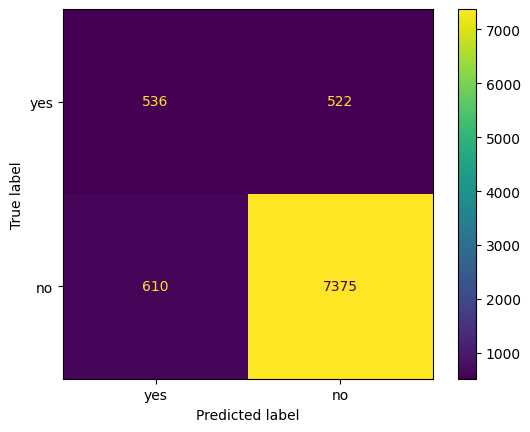

In [7]:
# [TỰ KIỂM TRA]
p_test_arr = np.asarray(p_test) if p_test is not None else np.asarray([])
y_test_05_arr = np.asarray(y_test_05) if y_test_05 is not None else np.asarray([])
y_test_tau_arr = np.asarray(y_test_tau) if y_test_tau is not None else np.asarray([])
assert p_test_arr.shape == (len(test),) and np.isfinite(p_test_arr).all() and ((p_test_arr >= 0) & (p_test_arr <= 1)).all(), "CHƯA ĐẠT: p_test phải là xác suất hữu hạn trong [0, 1] cho mỗi khách."
assert y_test_05_arr.shape == (len(test),) and y_test_tau_arr.shape == (len(test),), "CHƯA ĐẠT: cần một dự đoán cho mỗi khách ở cả hai ngưỡng."
assert set(np.unique(y_test_05_arr)).issubset({"yes", "no"}) and set(np.unique(y_test_tau_arr)).issubset({"yes", "no"}), "CHƯA ĐẠT: nhãn dự đoán chỉ được là yes/no."
assert np.array_equal(y_test_05_arr, np.where(p_test_arr >= 0.5, "yes", "no")), "CHƯA ĐẠT: y_test_05 phải được tính từ p_test ở ngưỡng 0,5."
assert np.array_equal(y_test_tau_arr, np.where(p_test_arr >= tau_sao, "yes", "no")), "CHƯA ĐẠT: y_test_tau phải được tính từ p_test ở ngưỡng tau*."
ket_qua_test = pd.DataFrame({"ngưỡng 0,5": chi_so(test["y"], y_test_05_arr),
                             f"ngưỡng tau* = {tau_sao}": chi_so(test["y"], y_test_tau_arr)}).T.round(3)
print("ĐẠT: đã đánh giá trên test."); display(ket_qua_test)
ConfusionMatrixDisplay.from_predictions(test["y"], y_test_tau_arr, labels=["yes", "no"]); plt.show()

`[MINH HỌA]` Diễn giải theo nghiệp vụ: nếu ngân hàng chỉ gọi những khách được mô hình chọn, so với gọi ngẫu nhiên **cùng số cuộc gọi**:

In [8]:
(tp, fn), (fp, tn) = confusion_matrix(test["y"], y_test_tau, labels=["yes", "no"])
so_cuoc_goi, ty_le_chung = tp + fp, (test["y"] == "yes").mean()
print(f"Mô hình chọn {so_cuoc_goi} trong {len(test)} khách ({so_cuoc_goi / len(test):.1%} danh sách) để gọi.")
print(f"Trong đó {tp} khách đồng ý: tỉ lệ thành công {tp / so_cuoc_goi:.1%}, so với {ty_le_chung:.1%} nếu gọi ngẫu nhiên "
      f"(kỳ vọng khoảng {ty_le_chung * so_cuoc_goi:.0f} khách) — gấp {tp / so_cuoc_goi / ty_le_chung:.1f} lần.")
print(f"Số khách đồng ý được tìm thấy: {tp} / {tp + fn} ({tp / (tp + fn):.1%}); bị bỏ lỡ: {fn}.")

Mô hình chọn 1146 trong 9043 khách (12.7% danh sách) để gọi.
Trong đó 536 khách đồng ý: tỉ lệ thành công 46.8%, so với 11.7% nếu gọi ngẫu nhiên (kỳ vọng khoảng 134 khách) — gấp 4.0 lần.
Số khách đồng ý được tìm thấy: 536 / 1058 (50.7%); bị bỏ lỡ: 522.


`[BÁO CÁO]` Đọc ma trận nhầm lẫn **theo nghiệp vụ**: gọi bao nhiêu khách, bao nhiêu khách đồng ý, tỉ lệ thành công so với gọi ngẫu nhiên, bỏ lỡ bao nhiêu khách. So với ngưỡng 0,5, ngưỡng τ\* làm Precision-yes và Recall-yes thay đổi như thế nào?

**Trả lời:** Ở ngưỡng τ* = 0,6, mô hình chọn gọi 1.146 trong 9.043 khách (12,7%), trong đó có 536 khách đồng ý và 610 khách không đồng ý. Tỉ lệ thành công là 46,8%, gấp khoảng 4 lần mức 11,7% khi gọi ngẫu nhiên cùng số cuộc gọi (kỳ vọng khoảng 134 khách đồng ý). Mô hình tìm được 536/1.058 khách đồng ý (50,7%) và bỏ lỡ 522 khách. So với ngưỡng 0,5, Precision-yes tăng từ 0,380 lên 0,468, còn Recall-yes giảm từ 0,595 xuống 0,507.

## 4.3 `[YÊU CẦU]` So sánh validation và test
Yêu cầu sinh viên hoàn thành dòng `test` của bảng so sánh **cùng mô hình, cùng ngưỡng τ\*** trên hai tập (dùng cho **Bảng 17**).

In [9]:
so_sanh = pd.DataFrame({"validation": chi_so(val["y"], y_val_tau) | {"tỉ lệ yes": (val["y"] == "yes").mean()},
                        "test": chi_so(test["y"], y_test_tau) | {"tỉ lệ yes": (test["y"] == "yes").mean()}}).T     # YÊU CẦU: tương tự dòng validation, dùng test và y_test_tau
so_sanh

,accuracy,precision_yes,recall_yes,f1_yes,tỉ lệ yes
validation,0.871157,0.454852,0.509452,0.480606,0.117010
test,0.874820,0.467714,0.506616,0.486388,0.116997


`[KIẾN THỨC]` **Cách đọc bảng.** Ba tập được chia ngẫu nhiên từ cùng một dữ liệu và chỉ **phân tầng theo nhãn `y`**, nên tỉ lệ `yes` được giữ gần nhau (có thể lệch nhẹ do số lượng nguyên). Cách chia này **không bảo đảm** các biến đầu vào có cùng phân phối; cần so sánh các thuộc tính nếu muốn kết luận về độ cân bằng của chúng. Chênh lệch giữa validation và test vì vậy chủ yếu đến từ hai nguồn:
- **dao động ngẫu nhiên** do mỗi tập chỉ có khoảng 1.058 khách `yes`: chênh lệch Recall 0,01 chỉ tương ứng khoảng 10 khách;
- **lạc quan do lựa chọn**: số nơ-ron, mô hình và ngưỡng đều được chọn vì tốt nhất trên validation, nên điểm validation thường cao hơn một chút so với dữ liệu mới.

Trong thực tế, khách hàng của các chiến dịch sau có thể khác khách hàng trong dữ liệu (dữ liệu sắp xếp theo thời gian 2008–2010); phép chia ngẫu nhiên không kiểm tra được điều này.

`[BÁO CÁO]` Viết **một đoạn (3–4 câu)**: so sánh F1, Precision, Recall của hai tập; chênh lệch lớn hay nhỏ so với dao động ngẫu nhiên; điểm test có thể dùng để báo cáo cho ngân hàng không và cần lưu ý gì.

**Trả lời:** Với cùng mô hình E5 và ngưỡng 0,6, F1-yes tăng từ 0,4806 trên validation lên 0,4864 trên test, Precision-yes tăng từ 0,4549 lên 0,4677, còn Recall-yes giảm nhẹ từ 0,5095 xuống 0,5066. Các chênh lệch nhỏ và phù hợp với dao động ngẫu nhiên giữa hai mẫu; riêng Recall giảm tương ứng tìm được ít hơn 3 khách đồng ý. Có thể dùng điểm test để báo cáo cho ngân hàng như kết quả đánh giá độc lập trên dữ liệu cùng nguồn, vì mô hình và ngưỡng đã được khóa trước khi đánh giá. Tuy nhiên, phép chia ngẫu nhiên từ dữ liệu giai đoạn 2008–2010 chưa kiểm chứng khả năng áp dụng cho các chiến dịch tương lai khi đặc điểm khách hàng có thể thay đổi.

`[CÂU HỎI SUY NGẪM]` (Câu 1) Nếu F1-yes trên test thấp hơn validation 0,01, có nên quay lại tuần 3 để chọn mô hình khác không?

**Trả lời:** Không nên quay lại tuần 3 để chọn mô hình khác vì lựa chọn dựa trên kết quả test sẽ làm mất tính độc lập của tập test. Cần giữ nguyên quyết định đã khóa, báo cáo trung thực và giải thích chênh lệch có thể do dao động ngẫu nhiên hoặc sự lạc quan khi lựa chọn trên validation.

## 4.4 `[YÊU CẦU]` Phân tích lỗi theo nhóm khách hàng
Một mô hình có thể tốt với nhóm khách này nhưng kém với nhóm khác. Hàm `theo_nhom(cot)` tính các chỉ số trên test **riêng cho từng giá trị** của một thuộc tính. Yêu cầu sinh viên hoàn thành dòng tính chỉ số trong hàm (dùng `chi_so` với cột `y` và cột `du_doan` của nhóm `d`).

In [10]:
bang_test = test.assign(p_yes=p_test.round(3), du_doan=y_test_tau)

In [11]:
def theo_nhom(cot):
    bang_nhom = {}
    for gia_tri, d in bang_test.groupby(cot, observed=True):
        bang_nhom[gia_tri] = chi_so(d["y"], d["du_doan"]) | {"số khách": len(d), "số khách yes": int((d["y"] == "yes").sum())}    # YÊU CẦU: chi_so(...) | {"số khách": len(d), "số khách yes": int((d["y"] == "yes").sum())}
    return pd.DataFrame(bang_nhom).T.round(3)

display(theo_nhom("contact")); display(theo_nhom("poutcome"))

,accuracy,precision_yes,recall_yes,f1_yes,số khách,số khách yes
cellular,0.840,0.479,0.553,0.513,5820.0,888.0
telephone,0.834,0.368,0.642,0.467,589.0,67.0
unknown,0.961,0.500,0.019,0.037,2634.0,103.0


,accuracy,precision_yes,recall_yes,f1_yes,số khách,số khách yes
failure,0.812,0.375,0.536,0.441,1012.0,140.0
other,0.783,0.416,0.597,0.490,355.0,62.0
success,0.650,0.650,1.000,0.788,306.0,199.0
unknown,0.897,0.408,0.342,0.373,7370.0,657.0


In [12]:
# [TỰ KIỂM TRA]
nhom = theo_nhom("contact")
assert "recall_yes" in nhom.columns and len(nhom) == 3, "CHƯA ĐẠT: hàm theo_nhom phải trả về các chỉ số cho từng giá trị."
print("ĐẠT: đã có bảng theo nhóm (dùng cho Bảng 19). Có thể thử thêm theo_nhom(\"job\") hoặc theo nhóm tuổi.")

ĐẠT: đã có bảng theo nhóm (dùng cho Bảng 19). Có thể thử thêm theo_nhom("job") hoặc theo nhóm tuổi.


`[BÁO CÁO]` Nhóm nào có Recall-yes thấp nhất (mô hình bỏ lỡ nhiều khách nhất)? Nhóm đó có bao nhiêu khách `yes`? Đưa ra **một giả thuyết** giải thích, có liên hệ với các nhận xét EDA ở tuần 1.

**Trả lời:** Nhóm `contact = unknown` có Recall-yes thấp nhất trong hai bảng, đạt 0,019; trong 103 khách `yes`, mô hình chỉ tìm được 2 khách và bỏ lỡ 101 khách. Giả thuyết là mô hình học được xu hướng ít đồng ý của nhóm này trong train (EDA tuần 1 ghi nhận tỉ lệ đồng ý chỉ 4,3%), nên nhiều khách `yes` vẫn nhận xác suất dưới ngưỡng 0,6. Đây là nhóm có tỉ lệ bỏ lỡ cao nhất; nếu xét số khách bỏ lỡ tuyệt đối trong bảng `contact`, nhóm `cellular` lớn nhất với 397 khách. Riêng trong bảng `poutcome`, nhóm `unknown` có Recall-yes thấp nhất là 0,342, với 657 khách `yes`, trong đó 432 khách bị bỏ lỡ.

## 4.5 `[YÊU CẦU]` Phân tích sáu trường hợp lỗi
Yêu cầu sinh viên lấy **3 khách bị bỏ lỡ** (thật `yes`, dự đoán `no`) và **3 khách bị gọi nhầm** (thật `no`, dự đoán `yes`) bằng seed cá nhân, theo mẫu `DataFrame.sample(3, random_state=S_SV)`.

In [13]:
loi_bo_lo = bang_test.query("y == 'yes' and du_doan == 'no'")
loi_goi_nham = bang_test.query("y == 'no' and du_doan == 'yes'")
print("Số khách bị bỏ lỡ:", len(loi_bo_lo), "| số khách bị gọi nhầm:", len(loi_goi_nham))

Số khách bị bỏ lỡ: 522 | số khách bị gọi nhầm: 610


In [14]:
mau_loi = pd.concat([
    loi_bo_lo.sample(3, random_state=S_SV),
    loi_goi_nham.sample(3, random_state=S_SV)
])     # YÊU CẦU: pd.concat([...]) gồm 3 khách từ loi_bo_lo và 3 khách từ loi_goi_nham, random_state=S_SV

In [15]:
# [TỰ KIỂM TRA]
assert mau_loi is not None and len(mau_loi) == 6, "CHƯA ĐẠT: cần sáu trường hợp lỗi."
assert ((mau_loi["y"] == "yes") & (mau_loi["du_doan"] == "no")).sum() == 3, "CHƯA ĐẠT: cần đúng 3 khách bị bỏ lỡ."
assert ((mau_loi["y"] == "no") & (mau_loi["du_doan"] == "yes")).sum() == 3, "CHƯA ĐẠT: cần đúng 3 khách bị gọi nhầm."
assert mau_loi["ma_dong"].nunique() == 6, "CHƯA ĐẠT: sáu mã dòng phải khác nhau."
print("ĐẠT: có 3 khách bị bỏ lỡ và 3 khách bị gọi nhầm.")
mau_loi[["ma_dong", "age", "job", "balance", "contact", "month", "campaign", "pdays", "poutcome", "y", "du_doan", "p_yes"]]

ĐẠT: có 3 khách bị bỏ lỡ và 3 khách bị gọi nhầm.


,ma_dong,age,job,balance,contact,month,campaign,pdays,poutcome,y,du_doan,p_yes
4081,dong:11712,60,retired,1690,unknown,jun,4,-1,unknown,yes,no,0.130
2481,dong:18051,41,blue-collar,0,cellular,jul,2,-1,unknown,yes,no,0.401
2257,dong:21621,43,management,483,cellular,aug,6,-1,unknown,yes,no,0.272
8999,dong:40923,44,self-employed,163,cellular,aug,1,100,success,no,yes,0.915
1044,dong:39795,55,technician,0,cellular,jun,1,91,success,no,yes,0.849
1936,dong:41544,72,retired,17739,cellular,sep,4,-1,unknown,no,yes,0.796


`[MINH HỌA]` Để có **bằng chứng** thay cho phỏng đoán, hàm `giai_thich` cho biết mô hình đã dựa vào điều gì (dùng cho **Mục 6.3**):
- với **MLP** (và rừng ngẫu nhiên), không đọc trực tiếp được trọng số, nên dùng phép **thay thế từng thuộc tính**: lần lượt thay một thuộc tính của khách bằng giá trị phổ biến nhất trong train (giá trị xuất hiện nhiều nhất với thuộc tính phân loại, trung vị với thuộc tính số), giữ nguyên các thuộc tính khác, rồi xem `p_yes` thay đổi bao nhiêu. Đây là so sánh với một trường hợp thay thế, **không phải quan hệ nhân quả hay đóng góp duy nhất**; các thuộc tính có thể tương tác với nhau.
- với hồi quy logistic là các **đóng góp** lớn nhất (giá trị đặc trưng × hệ số);
- với kNN là nhãn của các láng giềng gần nhất.

In [16]:
def giai_thich(chi_muc):
    x = bang_test.loc[[chi_muc]]
    bo_tien_xu_ly, cuoi = mo_hinh[-2], mo_hinh[-1]
    Z = mo_hinh[:-1].transform(x)
    Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
    ten = bo_tien_xu_ly.get_feature_names_out()
    if isinstance(cuoi, LogisticRegression):
        dong_gop = pd.Series(Z[0] * cuoi.coef_[0], index=ten)
        manh = dong_gop[dong_gop != 0].sort_values(key=abs, ascending=False)[:5]
        return "đóng góp mạnh nhất (dương: đẩy về yes): " + ", ".join(f"{k} {v:+.2f}" for k, v in manh.items())
    if isinstance(cuoi, KNeighborsClassifier):
        _, lang_gieng = cuoi.kneighbors(Z)
        return f"trong {cuoi.n_neighbors} khách gần nhất ở train có {(train['y'].to_numpy()[lang_gieng[0]] == 'yes').sum()} khách yes"
    # MLP, rừng ngẫu nhiên: thay từng thuộc tính bằng giá trị phổ biến nhất trong train
    pho_bien = {c: train[c].mode()[0] for c in THUOC_TINH_PL} | {c: train[c].median() for c in THUOC_TINH_SO}
    p0 = mo_hinh.predict_proba(x)[0, cot_yes]
    thay_doi = {c: mo_hinh.predict_proba(x.assign(**{c: pho_bien[c]}))[0, cot_yes] - p0
                for c in THUOC_TINH_PL + THUOC_TINH_SO if x[c].iloc[0] != pho_bien[c]}
    manh = sorted(thay_doi.items(), key=lambda kv: -abs(kv[1]))[:3]
    return "thay bằng giá trị phổ biến, p_yes thay đổi: " + ", ".join(f"{c} {x[c].iloc[0]} → {pho_bien[c]:g} ({d:+.2f})" if c in THUOC_TINH_SO
                                                                      else f"{c} {x[c].iloc[0]} → {pho_bien[c]} ({d:+.2f})" for c, d in manh)

for i in mau_loi.index:
    r = mau_loi.loc[i]
    print(f"{r['ma_dong']} [{'bỏ lỡ' if r['y'] == 'yes' else 'gọi nhầm'}, p_yes = {r['p_yes']}]\n   {giai_thich(i)}\n")

dong:11712 [bỏ lỡ, p_yes = 0.13]
   thay bằng giá trị phổ biến, p_yes thay đổi: contact unknown → cellular (+0.58), job retired → blue-collar (+0.06), day 20 → 16 (+0.04)

dong:18051 [bỏ lỡ, p_yes = 0.401]
   thay bằng giá trị phổ biến, p_yes thay đổi: marital divorced → married (-0.15), day 30 → 16 (+0.08), education primary → secondary (-0.04)

dong:21621 [bỏ lỡ, p_yes = 0.272]
   thay bằng giá trị phổ biến, p_yes thay đổi: month aug → may (+0.28), day 19 → 16 (+0.11), campaign 6 → 2 (+0.05)

dong:40923 [gọi nhầm, p_yes = 0.915]
   thay bằng giá trị phổ biến, p_yes thay đổi: poutcome success → unknown (-0.36), pdays 100 → -1 (-0.20), previous 3 → 0 (-0.17)

dong:39795 [gọi nhầm, p_yes = 0.849]
   thay bằng giá trị phổ biến, p_yes thay đổi: poutcome success → unknown (-0.26), pdays 91 → -1 (-0.10), previous 1 → 0 (-0.04)

dong:41544 [gọi nhầm, p_yes = 0.796]
   thay bằng giá trị phổ biến, p_yes thay đổi: job retired → blue-collar (-0.12), age 72 → 39 (-0.10), month sep → may (-0.07)



`[BÁO CÁO]` Với **mỗi khách** trong 6 khách, trả lời ba câu hỏi theo bảng dưới đây (chép bảng vào báo cáo):

| Mã dòng | Mô hình nhầm điều gì? | Bằng chứng (đặc điểm khách, đầu ra của `giai_thich`, p_yes) | Giải thích (*giả thuyết*) và đề xuất |
|---|---|---|---|
| dong:11712 | Bỏ lỡ: thật `yes`, dự đoán `no`. | Khách 60 tuổi, đã nghỉ hưu, `contact = unknown`, `poutcome = unknown`, `p_yes = 0,130 < 0,6`. Thay `contact: unknown → cellular` làm xác suất tăng 0,58; thay `job: retired → blue-collar` tăng 0,06. | Có thể thông tin kênh liên lạc `unknown` khiến mô hình đánh giá thấp khách này, phù hợp với Recall thấp của nhóm ở mục 4.4. Đề xuất kiểm tra nguồn và bổ sung thông tin kênh liên lạc nếu có. |
| dong:18051 | Bỏ lỡ: thật `yes`, dự đoán `no`. | Khách 41 tuổi, nghề `blue-collar`, số dư 0, chưa từng được liên hệ ở chiến dịch trước (`pdays = -1`), `p_yes = 0,401 < 0,6`. Thay `marital: divorced → married` làm xác suất giảm 0,15; thay `day: 30 → 16` tăng 0,08. | Có thể các thuộc tính hiện có chưa phản ánh đủ nhu cầu gửi tiết kiệm của khách; các phép thay trên chưa xác định được một nguyên nhân duy nhất của lỗi. Đề xuất thu thập thêm thông tin về nhu cầu và mức độ quan tâm gần đây. |
| dong:21621 | Bỏ lỡ: thật `yes`, dự đoán `no`. | Khách 43 tuổi, nghề `management`, tháng 8, đã liên lạc 6 lần trong chiến dịch, `poutcome = unknown`, `p_yes = 0,272 < 0,6`. Thay `month: aug → may` làm xác suất tăng 0,28; `day: 19 → 16` tăng 0,11; `campaign: 6 → 2` tăng 0,05. | Có thể tổ hợp thời điểm và số lần liên lạc khiến mô hình đánh giá thấp khách dù khách thực sự đồng ý. Đề xuất nghiên cứu tương tác giữa các thuộc tính này trên train/validation trong lần phát triển sau; chưa thể kết luận đổi thời điểm gọi sẽ làm khách đồng ý. |
| dong:40923 | Gọi nhầm: thật `no`, dự đoán `yes`. | Khách 44 tuổi, nghề `self-employed`, `poutcome = success`, `pdays = 100`, `previous = 3`, `p_yes = 0,915 ≥ 0,6`. Thay `poutcome: success → unknown` làm xác suất giảm 0,36; `pdays: 100 → -1` giảm 0,20; `previous: 3 → 0` giảm 0,17. | Có thể lịch sử chiến dịch thuận lợi khiến mô hình dự đoán đồng ý, trong khi nhu cầu hiện tại đã khác. Đề xuất bổ sung thông tin cập nhật về nhu cầu và phản hồi gần nhất, vì thành công trước đây không bảo đảm lần này đồng ý. |
| dong:39795 | Gọi nhầm: thật `no`, dự đoán `yes`. | Khách 55 tuổi, nghề `technician`, số dư 0, `poutcome = success`, `pdays = 91`, `previous = 1`, `p_yes = 0,849 ≥ 0,6`. Thay `poutcome: success → unknown` làm xác suất giảm 0,26; `pdays: 91 → -1` giảm 0,10; `previous: 1 → 0` giảm 0,04. | Có thể mô hình học xu hướng đồng ý cao của nhóm từng có chiến dịch thành công nhưng chưa phân biệt được ngoại lệ này. Đề xuất nghiên cứu thêm tín hiệu về tình trạng tài chính và nhu cầu hiện tại, rồi kiểm chứng trên train/validation trong lần phát triển sau. |
| dong:41544 | Gọi nhầm: thật `no`, dự đoán `yes`. | Khách 72 tuổi, đã nghỉ hưu, số dư 17.739, liên lạc tháng 9, `poutcome = unknown`, `p_yes = 0,796 ≥ 0,6`. Thay `job: retired → blue-collar` làm xác suất giảm 0,12; `age: 72 → 39` giảm 0,10; `month: sep → may` giảm 0,07. | Có thể khách mang những đặc điểm thường gắn với nhóm đồng ý nhưng bản thân lại không đồng ý; EDA tuần 1 cũng ghi nhận tỉ lệ đồng ý cao ở nhóm trên 60 tuổi. Đề xuất bổ sung thông tin về nhu cầu cá nhân để phân biệt các khách có đặc điểm tương tự. |

Các nhóm lỗi thường gặp: khách thuộc nhóm có thông tin `unknown`; khách chưa từng được liên hệ (không có lịch sử); xác suất sát ngưỡng; khách có đặc điểm giống nhóm đa số nhưng có nhãn ngược lại (dữ liệu không đủ thông tin để phân biệt).
**Không** thử các đề xuất trên test rồi báo cáo điểm mới.

## 4.6 `[NÂNG CAO — không bắt buộc]` Khoảng tin cậy bootstrap
F1-yes trên test được tính từ một mẫu khách hàng; với một mẫu khác cùng nguồn, con số này sẽ dao động. `scipy.stats.bootstrap` ước lượng mức dao động: lấy mẫu có hoàn lại từ chính tập test 1000 lần, tính F1-yes mỗi lần, rồi lấy khoảng chứa 95% giá trị ở giữa (phương pháp phân vị).

In [17]:
from scipy.stats import bootstrap      # bỏ dấu # ở các dòng dưới để thực hiện (khoảng 30 giây)
kq = bootstrap((test["y"].to_numpy(), y_test_tau), lambda a, b: f1_score(a, b, pos_label="yes"),
               paired=True, vectorized=False, n_resamples=1000, method="percentile", random_state=42)
print("F1-yes:", round(f1_score(test["y"], y_test_tau, pos_label="yes"), 3), "| khoảng tin cậy 95%:",
      [round(float(kq.confidence_interval.low), 3), round(float(kq.confidence_interval.high), 3)])

F1-yes: 0.486 | khoảng tin cậy 95%: [0.46, 0.512]


`[BÁO CÁO]` (nếu thực hiện) Viết một câu theo mẫu: *"F1-yes trên test là x (khoảng tin cậy 95%: [a; b], bootstrap, B = 1000)."*, kèm một câu diễn giải: khoảng rộng hay hẹp; các chênh lệch giữa mô hình nhỏ hơn độ rộng này chưa nên được xem là chắc chắn.

**Trả lời:** F1-yes trên test là 0,486 (khoảng tin cậy 95%: [0,460; 0,512], bootstrap, B = 1000). Khoảng có độ rộng 0,052, tương đối rộng so với các chênh lệch F1 chỉ vài phần nghìn, nên những chênh lệch giữa mô hình nhỏ hơn độ rộng này chưa nên được xem là chắc chắn nếu chỉ dựa vào điểm F1.

## 4.7 `[MINH HỌA]` Thử mô hình với khách hàng giả định
Kết quả dùng cho **Bảng 18**; sinh viên có thể bổ sung khách hàng của mình vào danh sách.

In [18]:
khach = pd.DataFrame([
    dict(age=22, job="student", marital="single", education="tertiary", default="no", balance=800, housing="no", loan="no",
         contact="cellular", day=15, month="mar", campaign=1, pdays=-1, previous=0, poutcome="unknown"),
    dict(age=45, job="blue-collar", marital="married", education="primary", default="no", balance=300, housing="yes", loan="yes",
         contact="unknown", day=20, month="may", campaign=4, pdays=-1, previous=0, poutcome="unknown"),
    dict(age=67, job="retired", marital="married", education="secondary", default="no", balance=5000, housing="no", loan="no",
         contact="telephone", day=10, month="oct", campaign=1, pdays=180, previous=2, poutcome="success"),
    dict(age=35, job="technician", marital="single", education="secondary", default="no", balance=1200, housing="yes", loan="no",
         contact="cellular", day=5, month="aug", campaign=2, pdays=-1, previous=0, poutcome="unknown"),
])
p = mo_hinh.predict_proba(khach)[:, cot_yes]
khach[["age", "job", "contact", "month", "poutcome"]].assign(p_yes=p.round(3), **{"ngưỡng 0,5": np.where(p >= 0.5, "yes", "no"),
                                                                                 "ngưỡng tau*": np.where(p >= tau_sao, "yes", "no")})

,age,job,contact,month,poutcome,p_yes,"ngưỡng 0,5",ngưỡng tau*
0,22,student,cellular,mar,unknown,0.851,yes,yes
1,45,blue-collar,unknown,may,unknown,0.103,no,no
2,67,retired,telephone,oct,success,0.951,yes,yes
3,35,technician,cellular,aug,unknown,0.431,no,no


`[BÁO CÁO]` Nhận xét các dự đoán có phù hợp với EDA không. Sau đó trả lời: nếu ngân hàng dùng mô hình để **chỉ** gọi những khách có `p_yes` cao, nhóm khách nào sẽ hầu như không bao giờ được gọi? Điều đó có vấn đề gì về công bằng hoặc về dữ liệu cho các chiến dịch sau? Ghi nhận vào mục **giới hạn** của báo cáo.

**Trả lời:** Các dự đoán nhìn chung phù hợp với EDA tuần 1: khách 22 tuổi được dự đoán `yes` với `p_yes = 0,851`, phù hợp với tỉ lệ đồng ý cao của nhóm trẻ và tháng 3; khách nghỉ hưu 67 tuổi có lịch sử `success` đạt `0,951`, phù hợp với xu hướng của nhóm trên 60 tuổi và nhóm từng có chiến dịch thành công. Khách 45 tuổi có `contact = unknown`, liên lạc tháng 5 đạt `0,103`, phù hợp với tỉ lệ đồng ý thấp của các nhóm này; khách kỹ thuật viên 35 tuổi đạt `0,431` và được dự đoán `no`, cũng phù hợp với tỉ lệ đồng ý của nhóm tuổi 30–40 và tháng 8 thấp hơn mức chung trong EDA. Cả bốn khách đều giữ nguyên nhãn ở hai ngưỡng; đây chỉ là sự phù hợp với xu hướng, chưa chứng minh nguyên nhân hay độ chính xác vì khách giả định không có nhãn thật.

Ở ngưỡng 0,6, nhóm `contact = unknown` gần như không được chọn gọi: từ bảng nhóm ở mục 4.4 có thể suy ra chỉ 4/2.634 khách được chọn, khoảng 0,15%; trong 103 khách thật sự đồng ý, mô hình chỉ tìm được 2 khách. Điều này có thể làm khách thiếu thông tin ít có cơ hội tiếp cận sản phẩm, dù trong nhóm vẫn có người đồng ý; tuy nhiên, chưa đủ bằng chứng để kết luận về công bằng trên mọi nhóm. Khi ít gọi nhóm bị đánh giá thấp, ngân hàng cũng ít thu được phản hồi mới từ nhóm đó, khiến dữ liệu chiến dịch sau thiên lệch theo cách chọn khách và có thể duy trì xu hướng bỏ sót. Đây là giới hạn cần ghi nhận; có thể đề xuất duy trì một phần cuộc gọi khảo sát ngẫu nhiên và theo dõi kết quả theo nhóm trong triển khai tương lai.

## Nộp cuối tuần 4
- [x] Mọi ô `[TỰ KIỂM TRA]` in **ĐẠT**; ô 4.1 xác nhận đúng mô hình đã khóa.
- [x] Đã có: bảng test ở hai ngưỡng, ma trận nhầm lẫn và diễn giải nghiệp vụ, bảng validation–test, bảng theo nhóm, bảng 6 lỗi.
- [x] **Hoàn thiện báo cáo:** Mục 5–7 (Bảng 15–21), Phụ lục A, B (Hình B.4), C; tài liệu tham khảo; khai báo công cụ hỗ trợ.
- [x] Báo cáo theo mẫu, **tối thiểu 20 trang** tính từ Mục 1 đến hết phụ lục (quy định của trường), không độn trang; xuất PDF tên `MSSV_ML_baocao.pdf`.
- [x] Nén bốn notebook đã chạy (`MSSV_tuan1.ipynb` … `MSSV_tuan4.ipynb`) và báo cáo PDF thành **một tệp** `MSSV_ML.zip`, nộp lên Moodle (https://hoctructuyen.sgu.edu.vn), mục nộp bài của đồ án (**một lần duy nhất**). Hạn nộp: ghi trong đề (mục *Sản phẩm nộp*).

---
### Gợi ý trả lời các câu hỏi suy ngẫm
<details><summary>Mở phần này sau khi đã tự trả lời</summary>

**Câu 1.** Không. Mô hình và ngưỡng đã được khóa; nếu chọn lại dựa trên test, test trở thành một tập validation thứ hai và không còn đánh giá độc lập. Chênh lệch 0,01 nằm trong mức dao động ngẫu nhiên (khoảng 10 khách). Cách làm đúng: báo cáo trung thực điểm test và giải thích chênh lệch.
</details>